In [3]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [4]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle

from notebooks.imports import *

### Config

In [5]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

me_type = "global"

## Helper Functions

In [6]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
    }

def get_pulse_coh_indices(data):
	# note indices for each pulse_type and each signed_coherence under each pulse_type
	pulse_type = data.pulse_type.unique()
	indices = {}
	for pt in pulse_type:
		indices[pt] = {}
		for sc in data.signed_coherence.unique():
			indices[pt][sc] = data[(data.pulse_type == pt) & (data.signed_coherence == sc)].agg_code.values

### Load and Preprocess data

In [7]:
with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
	motion_energy_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
print(len(motion_energy_dict))

data.reaction_time = (data.reaction_time * 1000).astype(int)
data = data[data.reaction_time < 3000]
data

113874


,agg_code,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,stimulus_seed,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,DBM11_10_1_1,0,uw,DBM11,10_1,1,0,False,100,1.0,1,1080,1.0,1.5,0.530901,25.0,0.0,0.500000,612658,True,0.416750,0.066680,-100.0,-3
1,DBM11_10_1_2,0,uw,DBM11,10_1,2,0,False,100,1.0,0,469,0.0,NaN,0.577326,25.0,0.0,13.689771,463182,False,0.416750,0.066680,100.0,0
2,DBM11_10_1_3,0,uw,DBM11,10_1,3,0,False,-100,-1.0,0,2171,1.0,1.5,0.556890,25.0,0.0,0.500000,165712,True,0.416750,0.066680,100.0,3
3,DBM11_10_1_4,0,uw,DBM11,10_1,4,0,False,-100,-1.0,0,476,1.0,1.5,0.548262,25.0,0.0,0.500000,418800,False,0.050010,0.066680,-100.0,0
4,DBM11_10_1_5,0,uw,DBM11,10_1,5,0,False,-100,-1.0,0,971,1.0,1.5,0.561377,25.0,0.0,0.500000,372882,False,0.233380,0.066680,-100.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113869,PSUIM9_9_1_346,300,ucla,PSUIM9,9_1,346,0,False,18,1.0,1,1108,1.0,2.6,1.000000,60.0,0.5,0.250000,346,True,0.029568,0.050560,100.0,1
113870,PSUIM9_9_1_347,300,ucla,PSUIM9,9_1,347,0,False,36,1.0,1,1598,1.0,2.6,1.000000,60.0,0.5,0.250000,347,False,NaN,NaN,NaN,0
113871,PSUIM9_9_1_348,300,ucla,PSUIM9,9_1,348,0,False,-9,-1.0,1,2292,0.0,0.0,1.000000,60.0,1.5,0.252608,348,False,NaN,NaN,NaN,0
113872,PSUIM9_9_1_349,300,ucla,PSUIM9,9_1,349,0,False,36,1.0,1,1706,1.0,2.6,1.000000,60.0,0.5,0.250000,349,True,0.240538,0.050291,100.0,2


## Acccuracy vs Reaction Time

In [8]:
import pandas as pd

def bin_accuracy(data, bin_width=100):
	# Compute bins using numpy
	bins = np.arange(0, 10000, bin_width)

	# Use np.digitize for faster binning of reaction times
	bin_indices = np.digitize(data.reaction_time, bins, right=False) - 1  # Subtract 1 to get the correct bin index

	# Add the bin index to the data
	data['bin'] = bin_indices

	# Calculate the mean outcome for each bin
	binned_accuracy = data.groupby('bin')['outcome'].mean().reset_index()

	# Calculate midpoints using bins directly (without applying lambda function)
	binned_accuracy['midpoint'] = bins[binned_accuracy['bin']] + bin_width / 2

	return binned_accuracy


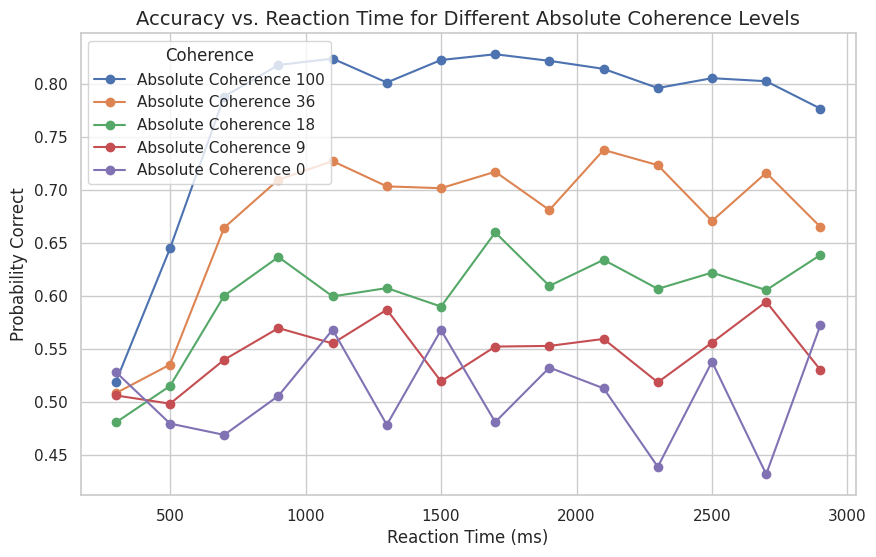

In [9]:
# Filter control data (pulse_type == 0)
control = data[data.pulse_type == 0]

# Add absolute coherence as a new column
control['absolute_coherence'] = control['signed_coherence'].abs()

# Create an empty dictionary to store binned accuracy for each absolute coherence level
binned_accuracies = {}

# Iterate over unique absolute coherence levels and bin the data separately for each
coherence_levels = control['absolute_coherence'].unique()
for coh in coherence_levels:
    coherence_data = control[control['absolute_coherence'] == coh]
    binned_accuracies[coh] = bin_accuracy(coherence_data, bin_width=200)

# Set up the plot
plt.figure(figsize=(10, 6))
for coh, binned_accuracy in binned_accuracies.items():
    plt.plot(binned_accuracy['midpoint'], binned_accuracy['outcome'],
            	marker='o', label=f'Absolute Coherence {coh}')
plt.xlabel('Reaction Time (ms)', fontsize=12)
plt.ylabel('Probability Correct', fontsize=12)
plt.title('Accuracy vs. Reaction Time for Different Absolute Coherence Levels', fontsize=14)
plt.grid(True)
plt.legend(title='Coherence')
plt.show()


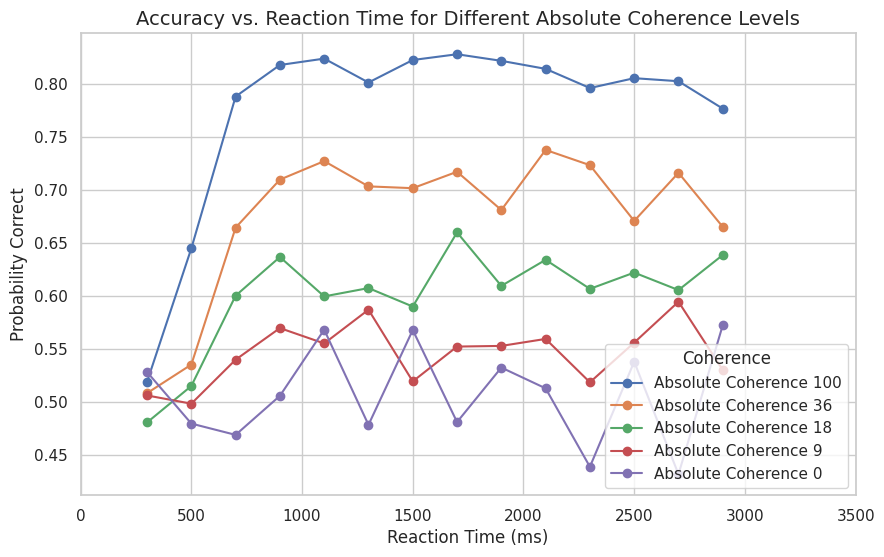

In [10]:
# Set up the plot
plt.figure(figsize=(10, 6))
for coh, binned_accuracy in binned_accuracies.items():
	plt.plot(binned_accuracy["midpoint"], binned_accuracy["outcome"], marker="o", label=f"Absolute Coherence {coh}")
plt.xlabel("Reaction Time (ms)", fontsize=12)
plt.ylabel("Probability Correct", fontsize=12)
plt.title("Accuracy vs. Reaction Time for Different Absolute Coherence Levels", fontsize=14)
plt.xlim(0, 3500)
plt.grid(True)
plt.legend(title="Coherence")
plt.show()


In [11]:
for rt in range(0, 10000, 500):
	n_trials = len(data[data.reaction_time < rt])
	percent = 100 * n_trials / len(data)
	print(f"Trials below {rt:5d} ms: {n_trials:5d} ({percent:5.2f}%)")


Trials below     0 ms:     0 ( 0.00%)
Trials below   500 ms: 13929 (16.41%)
Trials below  1000 ms: 41976 (49.45%)
Trials below  1500 ms: 60737 (71.55%)
Trials below  2000 ms: 71645 (84.40%)
Trials below  2500 ms: 79069 (93.15%)
Trials below  3000 ms: 84884 (100.00%)
Trials below  3500 ms: 84884 (100.00%)
Trials below  4000 ms: 84884 (100.00%)
Trials below  4500 ms: 84884 (100.00%)
Trials below  5000 ms: 84884 (100.00%)
Trials below  5500 ms: 84884 (100.00%)
Trials below  6000 ms: 84884 (100.00%)
Trials below  6500 ms: 84884 (100.00%)
Trials below  7000 ms: 84884 (100.00%)
Trials below  7500 ms: 84884 (100.00%)
Trials below  8000 ms: 84884 (100.00%)
Trials below  8500 ms: 84884 (100.00%)
Trials below  9000 ms: 84884 (100.00%)
Trials below  9500 ms: 84884 (100.00%)


--- Click rate Reliability

Coherence 100: Pulse Coherences [-100.  100.   nan]


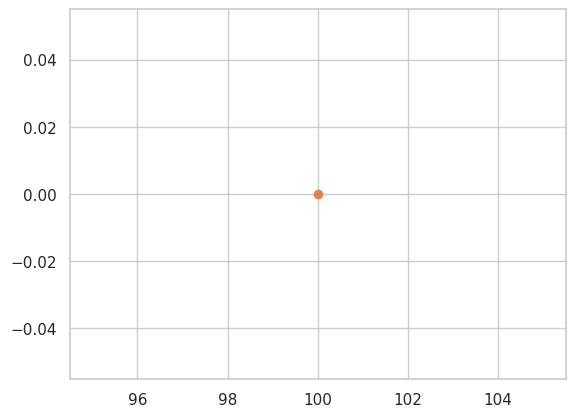

In [12]:
coherences = data.signed_coherence.unique()
pulse_cohs = data.pulse_coherence.unique()

# onset reliability by taking log ratio

for coh in coherences:
	temp = data[data.signed_coherence == coh]
	pulse_cohs = temp.pulse_coherence.unique()
	print(f"Coherence {coh}: Pulse Coherences {pulse_cohs}")
	for pc in pulse_cohs:
		k = np.log(coh / pc)
		plt.plot(coh, k, marker="o", label=f"Coherence {coh} / Pulse Coherence {pc}")
	break